# Customer Shopping Trends Analysis

Python exploration, SQLite analysis and a CSV export for the interactive dashboard. Place `shopping_trends_updated.csv` in the working directory and run the cells in order.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("shopping_trends_updated.csv")
df.head(10)

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually
5,6,46,Male,Sneakers,Footwear,20,Wyoming,M,White,Summer,2.9,Yes,Venmo,Standard,Yes,Yes,14,Venmo,Weekly
6,7,63,Male,Shirt,Clothing,85,Montana,M,Gray,Fall,3.2,Yes,Debit Card,Free Shipping,Yes,Yes,49,Cash,Quarterly
7,8,27,Male,Shorts,Clothing,34,Louisiana,L,Charcoal,Winter,3.2,Yes,Debit Card,Free Shipping,Yes,Yes,19,Credit Card,Weekly
8,9,26,Male,Coat,Outerwear,97,West Virginia,L,Silver,Summer,2.6,Yes,Venmo,Express,Yes,Yes,8,Venmo,Annually
9,10,57,Male,Handbag,Accessories,31,Missouri,M,Pink,Spring,4.8,Yes,PayPal,2-Day Shipping,Yes,Yes,4,Cash,Quarterly


In [3]:
print("Data Shape (Rows, Columns):", df.shape)
print("-" * 30)
print("Missing Data Check:")
print(df.isnull().sum())

Data Shape (Rows, Columns): (3900, 19)
------------------------------
Missing Data Check:
Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64


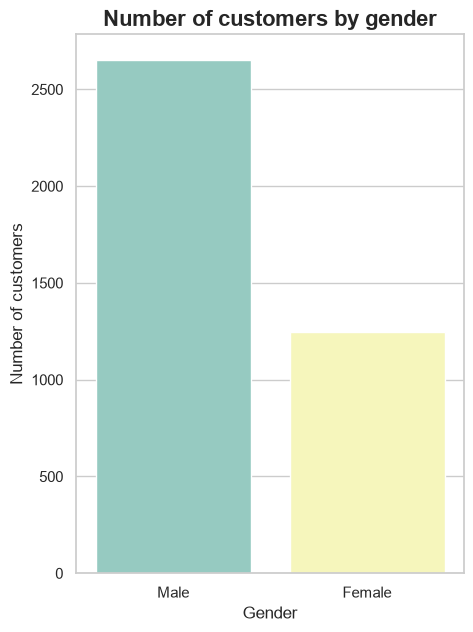

In [4]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(5,7))

sns.countplot(data=df, x="Gender", palette="Set3")

plt.title("Number of customers by gender", fontsize=16, fontweight="bold")

plt.xlabel("Gender", fontsize=12)

plt.ylabel('Number of customers', fontsize=12)

plt.show()

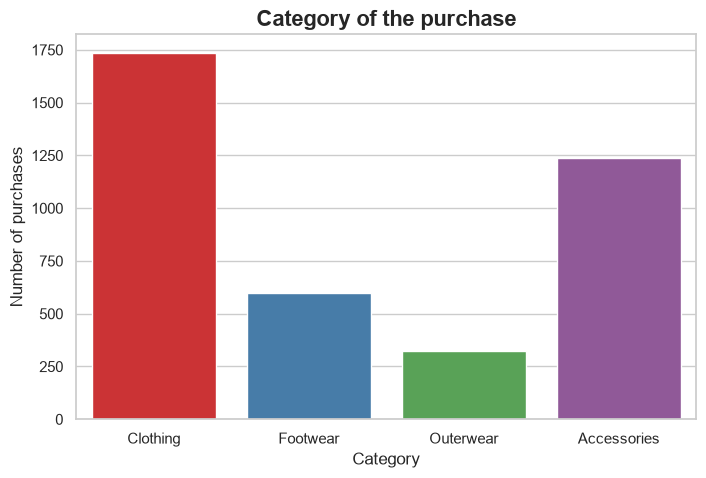

In [5]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Category", palette="Set1")

plt.title("Category of the purchase", fontsize=16, fontweight="bold")

plt.xlabel("Category", fontsize=12)

plt.ylabel('Number of purchases', fontsize=12)

plt.show()

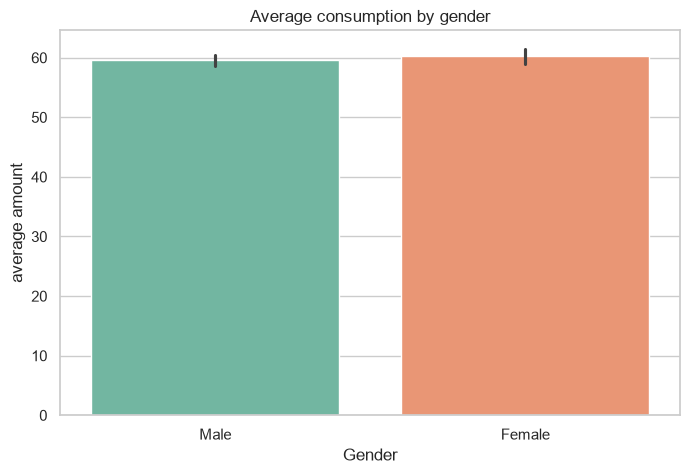

In [6]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,5))

sns.barplot(data=df, x ='Gender', y ="Purchase Amount (USD)", palette="Set2")

plt.title("Average consumption by gender", fontsize=12)

plt.xlabel("Gender",fontsize=12)

plt.ylabel("average amount")

plt.show()


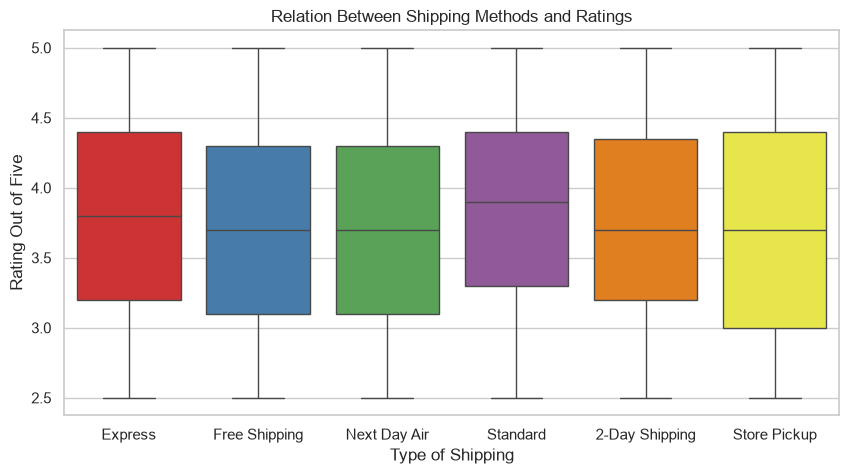

In [7]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(10,5))

sns.boxplot(data=df, x ='Shipping Type', y='Review Rating',palette='Set1')

plt.title('Relation Between Shipping Methods and Ratings')

plt.xlabel('Type of Shipping')

plt.ylabel('Rating Out of Five')

plt.show()


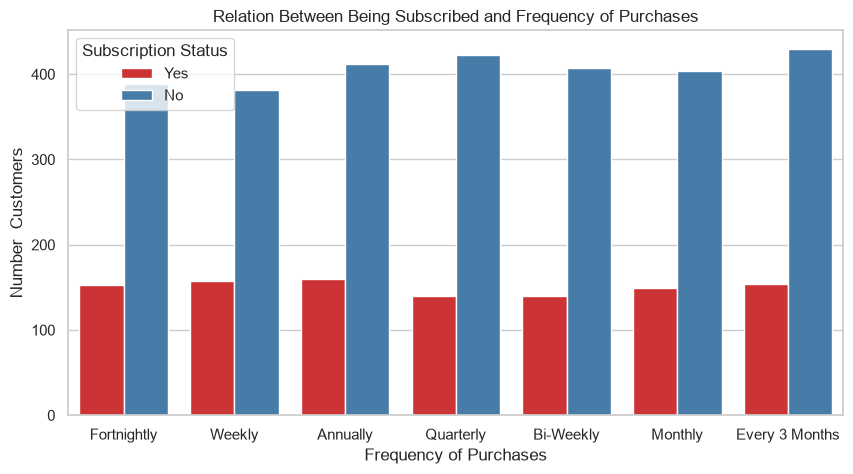

In [8]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(10,5))

sns.countplot(data=df, x='Frequency of Purchases',hue='Subscription Status', palette='Set1')

plt.title('Relation Between Being Subscribed and Frequency of Purchases')

plt.xlabel('Frequency of Purchases')

plt.ylabel('Number  Customers')

plt.show()

## SQL analysis with SQLite

Create an in-memory database from the existing DataFrame. Column names are normalized to lowercase snake_case; `Purchase Amount (USD)` becomes `purchase_amount_usd`. The same five queries are available in `analysis.sql`.

In [9]:
import sqlite3

sql_df = df.copy()
sql_df.columns = (
    sql_df.columns.str.strip()
    .str.lower()
    .str.replace(r"\W+", "_", regex=True)
    .str.strip("_")
)

conn = sqlite3.connect(":memory:")
sql_df.to_sql("shopping", conn, index=False, if_exists="replace")
print(f"Loaded {len(sql_df):,} records into the shopping table.")

Loaded 3,900 records into the shopping table.


### 1. Record counts and average purchase amount by category

In [10]:
query_1 = """
-- SQLite queries for Customer Shopping Trends Analysis.
-- Run the notebook's SQLite setup cell first to create and populate shopping.
-- Column names use lowercase snake_case, including purchase_amount_usd.

-- 1. Record counts and average purchase amount by category.
SELECT
    category,
    COUNT(*) AS num_records,
    ROUND(AVG(purchase_amount_usd), 2) AS average_purchase_amount
FROM shopping
GROUP BY category
ORDER BY num_records DESC;
"""
pd.read_sql_query(query_1, conn)

,category,num_records,average_purchase_amount
0,Clothing,1737,60.03
1,Accessories,1240,59.84
2,Footwear,599,60.26
3,Outerwear,324,57.17


### 2. Subscriber and non-subscriber comparison

In [11]:
query_2 = """
-- 2. Compare subscribers and non-subscribers.
SELECT
    subscription_status,
    COUNT(*) AS num_records,
    ROUND(AVG(purchase_amount_usd), 2) AS average_purchase_amount,
    ROUND(AVG(previous_purchases), 2) AS avg_previous_purchases
FROM shopping
GROUP BY subscription_status
ORDER BY subscription_status;
"""
pd.read_sql_query(query_2, conn)

,subscription_status,num_records,average_purchase_amount,avg_previous_purchases
0,No,2847,59.87,25.08
1,Yes,1053,59.49,26.08


### 3. Average review rating by shipping type

In [12]:
query_3 = """
-- 3. Average review rating by shipping type.
SELECT
    shipping_type,
    COUNT(*) AS num_records,
    ROUND(AVG(review_rating), 2) AS avg_review_rating
FROM shopping
GROUP BY shipping_type
ORDER BY AVG(review_rating) DESC;
"""
pd.read_sql_query(query_3, conn)

,shipping_type,num_records,avg_review_rating
0,Standard,654,3.82
1,Express,646,3.78
2,2-Day Shipping,627,3.76
3,Next Day Air,648,3.72
4,Free Shipping,675,3.72
5,Store Pickup,650,3.71


### 4. Categories above the overall average purchase amount

In [13]:
query_4 = """
-- 4. Categories whose average purchase amount exceeds the overall average.
SELECT
    category,
    COUNT(*) AS num_records,
    ROUND(AVG(purchase_amount_usd), 2) AS average_purchase_amount
FROM shopping
GROUP BY category
HAVING AVG(purchase_amount_usd) > (
    SELECT AVG(purchase_amount_usd)
    FROM shopping
)
ORDER BY AVG(purchase_amount_usd) DESC;
"""
pd.read_sql_query(query_4, conn)

,category,num_records,average_purchase_amount
0,Footwear,599,60.26
1,Clothing,1737,60.03
2,Accessories,1240,59.84


### 5. Purchase-frequency distribution within subscription groups

In [14]:
query_5 = """
-- 5. Purchase-frequency distribution within each subscription group.
-- Preserve the original frequency labels because their definitions are unverified.
WITH subscription_totals AS (
    SELECT
        subscription_status,
        COUNT(*) AS subscription_total
    FROM shopping
    GROUP BY subscription_status
),
frequency_counts AS (
    SELECT
        subscription_status,
        frequency_of_purchases,
        COUNT(*) AS frequency_count
    FROM shopping
    GROUP BY subscription_status, frequency_of_purchases
)
SELECT
    freq.subscription_status,
    freq.frequency_of_purchases,
    freq.frequency_count,
    totals.subscription_total,
    ROUND(
        100.0 * freq.frequency_count / totals.subscription_total,
        2
    ) AS percentage
FROM frequency_counts AS freq
JOIN subscription_totals AS totals
    ON freq.subscription_status = totals.subscription_status
ORDER BY
    freq.subscription_status,
    freq.frequency_count DESC,
    freq.frequency_of_purchases;
"""
pd.read_sql_query(query_5, conn)

,subscription_status,frequency_of_purchases,frequency_count,subscription_total,percentage
0,No,Every 3 Months,430,2847,15.10
1,No,Quarterly,423,2847,14.86
2,No,Annually,412,2847,14.47
3,No,Bi-Weekly,407,2847,14.30
4,No,Monthly,404,2847,14.19
5,No,Fortnightly,389,2847,13.66
6,No,Weekly,382,2847,13.42
7,Yes,Annually,160,1053,15.19
8,Yes,Weekly,157,1053,14.91
9,Yes,Every 3 Months,154,1053,14.62


## Export dashboard data

Create `shopping_dashboard.csv` for Looker Studio. `is_subscriber` is 1 for Yes and 0 for No; its average gives the subscription rate. In Colab, download the generated CSV from the Files panel. The original purchase-frequency labels are preserved.

In [15]:
dashboard_df = sql_df.copy()
dashboard_df["is_subscriber"] = (
    dashboard_df["subscription_status"]
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)
if dashboard_df["is_subscriber"].isna().any():
    raise ValueError("Unexpected subscription status: expected Yes or No.")

dashboard_df.to_csv("shopping_dashboard.csv", index=False)
print(f"Exported {len(dashboard_df):,} records to shopping_dashboard.csv")

Exported 3,900 records to shopping_dashboard.csv
